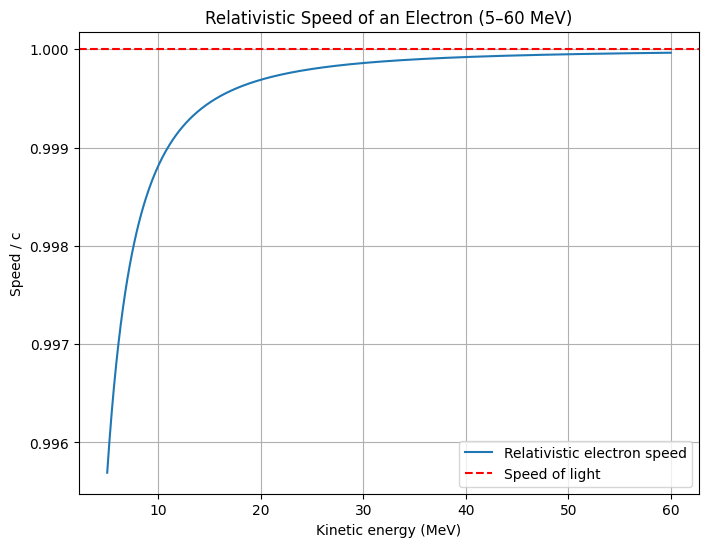

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def beta_gamma_from_K_MeV(K_MeV):
    K = K_MeV * MeV_to_J
    gamma = 1.0 + K / (m_e * c**2)
    beta = np.sqrt(1.0 - 1.0 / gamma**2)
    return beta, gamma


def lambda_from_current(I_A, tau, energy_MeV):
    """
    Returns (lambdaDens, Q, v)
    lambdaDens: linear charge density (C/m)
    Q: total charge in pulse (C)
    v: particle speed (m/s) 
    """
    beta, gamma = beta_gamma_from_K_MeV(energy_MeV)
    v = beta * c

    Q = I_A * tau
    L_eff = v * tau
    L_eff_rel = L_eff / gamma  # length contraction
    lambdaDens = Q / L_eff 
    relLambdaDens = Q / L_eff_rel
    return lambdaDens, relLambdaDens, Q, v, L_eff

def solve_retarded_time_constant_velocity(r, r0, v, t_obs):
    """
    Solve for retarded time t_ret for a charge at r0 moving with velocity v (m/s),
    observed at position r and observation time t_obs.
    The implicit equation is:
        t_ret = t_obs - | r - (r0 + v t_ret) | / c
    For constant v this becomes a quadratic in t_ret. Return the physical retarded root (<= t_obs).
    """
    R0 = r - r0
    v2 = np.dot(v, v)
    a = v2 - c**2
    b = 2.0 * (c**2 * t_obs - np.dot(R0, v))
    cc = np.dot(R0, R0) - (c**2) * (t_obs**2)

    # handle nearly lightlike velocity (a ~= 0) gracefully by fallback to iteration
    if abs(a) < 1e-16:
        # fallback: simple fixed-point iteration
        t_ret = t_obs - np.linalg.norm(r - (r0 + v * 0.0)) / c
        for _ in range(50):
            r_charge = r0 + v * t_ret
            t_ret_new = t_obs - np.linalg.norm(r - r_charge) / c
            if abs(t_ret_new - t_ret) < 1e-12:
                break
            t_ret = t_ret_new
        return t_ret

    disc = b*b - 4*a*cc
    if disc < 0:
        return np.nan
    sqrt_disc = np.sqrt(disc)
    t1 = (-b + sqrt_disc) / (2*a)
    t2 = (-b - sqrt_disc) / (2*a)

    # choose the root that is <= t_obs (retarded). If both are <= t_obs choose the larger one (closest to t_obs)
    candidates = []
    for tt in (t1, t2):
        if tt <= t_obs + 1e-12:
            candidates.append(tt)
    if candidates:
        # retarded time is the larger of the acceptable roots (closest but not after t_obs)
        return max(candidates)
    # if none <= t_obs (numerical edge), choose the smaller root
    return min(t1, t2)

def E_LW_exact(q, r, r0, beta, t_obs):
    """
    Exact Liénard–Wiechert E-field for constant velocity charge (uses exact retarded time).
    beta is dimensionless v/c vector.
    """
    v = beta * c
    t_ret = solve_retarded_time_constant_velocity(r, r0, v, t_obs)
    if not np.isfinite(t_ret):
        return np.array([np.nan, np.nan, np.nan])
    r_ret = r0 + v * t_ret
    R = r - r_ret
    R_mag = np.linalg.norm(R) + 1e-24
    n = R / R_mag

    beta_dot_n = np.dot(beta, n)
    beta2 = np.dot(beta, beta)
    gamma = 1.0 / np.sqrt(1.0 - beta2)

    coeff = q / (4.0 * np.pi * epsilon0)
    # velocity field piece (no acceleration): vector form used earlier
    E = coeff * ((n - beta) / (gamma**2 * (1.0 - beta_dot_n)**3 * R_mag**2))
    return E
def E_Lorentz_transform(q, r, beta):
    """
    Compute E by Lorentz-transforming the Coulomb field from the charge rest frame.
    """
    beta2 = np.dot(beta, beta)
    if beta2 == 0:
        rmag = np.linalg.norm(r) + 1e-24
        return q / (4.0 * np.pi * epsilon0) * (r / rmag**3)
    
    gamma = 1.0 / np.sqrt(1.0 - beta2)
    v_hat = beta / np.sqrt(beta2)
    
    # Decompose r into components parallel and perpendicular to v
    r_par = np.dot(r, v_hat) * v_hat
    r_perp = r - r_par
    
    # Correct transformation: parallel component expanded by gamma in rest frame
    r_prime = r_perp + gamma * r_par  # FIXED: gamma * r_par, not r_par/gamma
    rprime_mag = np.linalg.norm(r_prime) + 1e-24
    
    E_prime = q / (4.0 * np.pi * epsilon0) * (r_prime / rprime_mag**3)
    
    # Transform E' back to lab frame
    E_par = np.dot(E_prime, v_hat) * v_hat
    E_perp = E_prime - E_par
    E_lab = E_par + gamma * E_perp  # Perpendicular component enhanced by gamma
    
    return E_lab


# Physical constants (SI units)
m_e = 9.10938356e-31   # electron mass (kg)
c = 3.0e8              # speed of light (m/s)
eV = 1.602176634e-19   # Joules in one eV
MeV = 1e6 * eV         # Joules in one MeV
m_e = 9.10938356e-31       # kg
c = 299792458.0            # m/s
epsilon0 = 8.8541878128e-12 #electric constant
mu0 = 4*np.pi*1e-7 
e_charge = 1.602176634e-19 # charge of electron
MeV_to_J = 1e6 * 1.602176634e-19 # joules/mev

# Energy range: 5–60 MeV
E_MeV = np.linspace(5, 60, 500)  # kinetic energy in MeV
E_J = E_MeV * MeV

# Relativistic total energy and velocity
E_total = E_J + m_e * c**2
gamma = E_total / (m_e * c**2)
v = c * np.sqrt(1 - 1/gamma**2)

# Plot
plt.figure(figsize=(8,6))
plt.plot(E_MeV, v/c, label="Relativistic electron speed")
plt.axhline(1, color='r', linestyle='--', label="Speed of light")
plt.xlabel("Kinetic energy (MeV)")
plt.ylabel("Speed / c")
plt.title("Relativistic Speed of an Electron (5–60 MeV)")
plt.legend()
plt.grid(True)
plt.savefig("relativistic_speed.png")
plt.show()


In [2]:
# ----------------------------
# EXPERIMENT PARAMETERS
# ----------------------------
I_reported = 0.0000025 # Amperes
pulse_len = 12e-9      # s (5000 ns) 
energy_MeV = 40 # MeV
lambda_lit = 3.2e-9 # C/m from linac paper

# compute lambdas
lambda_avg, relLambdaDens, Q_total, v, L_eff= lambda_from_current(
    I_reported, pulse_len, energy_MeV,)

# Finite Line Calculation
# Based on EQ 2.2 from Griffiths EM
def finiteLine(lambda_density, z, L):
    """Return E (V/m) at distance z from center of finite line of length L with linear density lambda."""
    E = 1/(4 * np.pi * epsilon0) * (2 * lambda_density * L)/ (z * np.sqrt(z**2 + L**2))
    return E

L = L_eff / 2 # half length of pulse
beta = v/c
betaVal = beta
print("Results:")
print(f"Total pulse charge Q = {Q_total:.3e} C")
print(f"Length = {L_eff:.3e} M")
print(f"v = {v:.6e} m/s (beta = {beta:.6f})")
print(f"lambda_avg = {lambda_avg:.3e} C/m")
print(f"lambda_avg_rel = {relLambdaDens:.3e} C/m")



Results:
Total pulse charge Q = 3.000e-14 C
Length = 3.597e+00 M
v = 2.997686e+08 m/s (beta = 0.999920)
lambda_avg = 8.340e-15 C/m
lambda_avg_rel = 6.612e-13 C/m


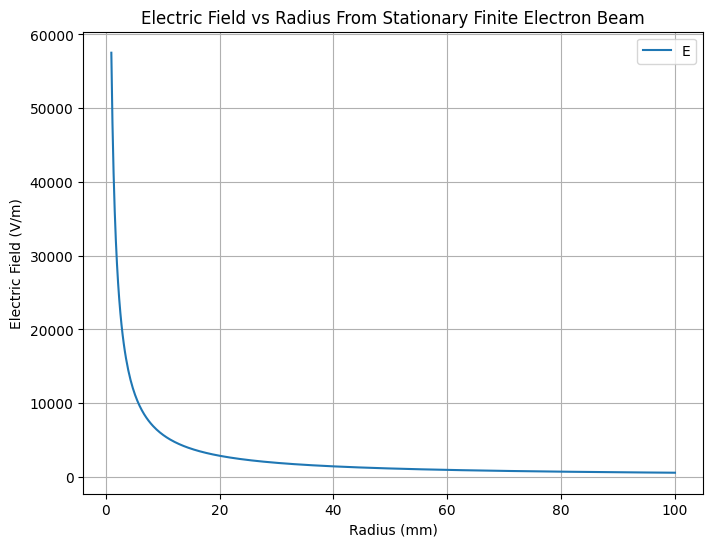

In [3]:
# Graphing E vs radius
radius = np.linspace(1e-3, 1e-1, 500) # m
E_finite = finiteLine(lambda_lit, radius, L)

plt.figure(figsize=(8,6))
plt.plot(radius*1e3, E_finite, label="E")
plt.xlabel("Radius (mm)")
plt.ylabel("Electric Field (V/m)")
plt.title("Electric Field vs Radius From Stationary Finite Electron Beam")
plt.legend()
plt.grid(True)
plt.savefig("electric_field_vs_radius.png")
plt.show()


/tmp/ipykernel_18110/1332089366.py:49: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.93, 0.99])


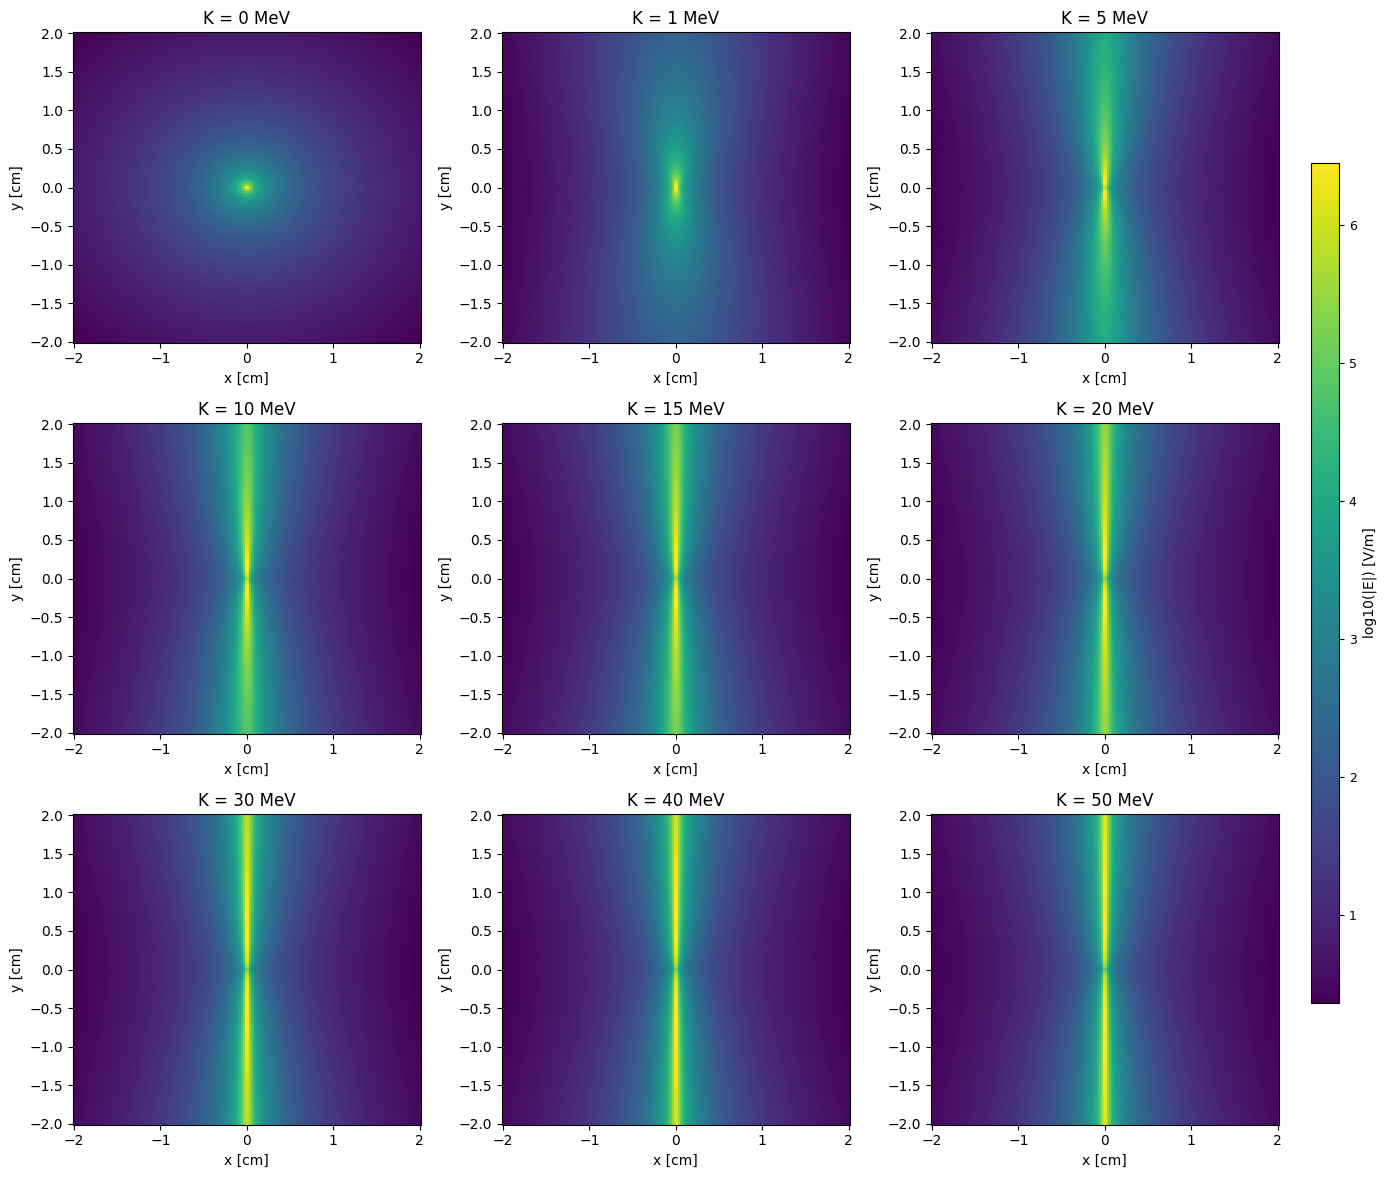

In [4]:
# ----------------------------
# Graphing 9 different speeds of particles
epsilon0 = 8.8541878128e-12
c = 299792458.0

# Parameters
q = 1e-9  # Coulomb
r0 = np.array([0.0, 0.0, 0.0])  # charge position at t=0 (will be used consistently)
t_obs = 0.0  # observation time


grid_size = 180
extent = 0.02  # ±2 cm
x = np.linspace(-extent, extent, grid_size)
y = np.linspace(-extent, extent, grid_size)
X, Y = np.meshgrid(x, y)

energies = [0, 1, 5, 10, 15, 20, 30, 40, 50]  # MeV (for electron)
E_Lorentz_mag = np.zeros((len(energies), grid_size, grid_size))

# ---------------- Field computation ----------------

for k, K in enumerate(energies):
    beta_val, gamma_val = beta_gamma_from_K_MeV(K)
    beta_vec = np.array([beta_val, 0.0, 0.0])
    for i in range(grid_size):
        for j in range(grid_size):
            r = np.array([X[i, j], Y[i, j], 0.0])
            E = E_Lorentz_transform(q, r - beta_vec * c * t_obs, beta_vec)
            E_Lorentz_mag[k, i, j] = np.linalg.norm(E)
# ---------------- Plotting 3×3 grid ----------------
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for k, ax in enumerate(axes.flat):
    im = ax.pcolormesh(
        X*100, Y*100, np.log10(E_Lorentz_mag[k] + 1e-30),
        shading='auto'
    )
    ax.set_title(f"K = {energies[k]} MeV")
    ax.set_xlabel("x [cm]")
    ax.set_ylabel("y [cm]")

# Add colorbar BEFORE tight_layout and show
fig.subplots_adjust(right=0.92)
cbar_ax = fig.add_axes([0.94, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax, label='log10(|E|) [V/m]')
cbar.ax.tick_params(labelsize=9)

# NOW do tight_layout and show/save
plt.tight_layout(rect=[0, 0, 0.93, 0.99])
plt.savefig("Lorentz_field_9panel.png", dpi=200)
plt.show()



-1.5e-07


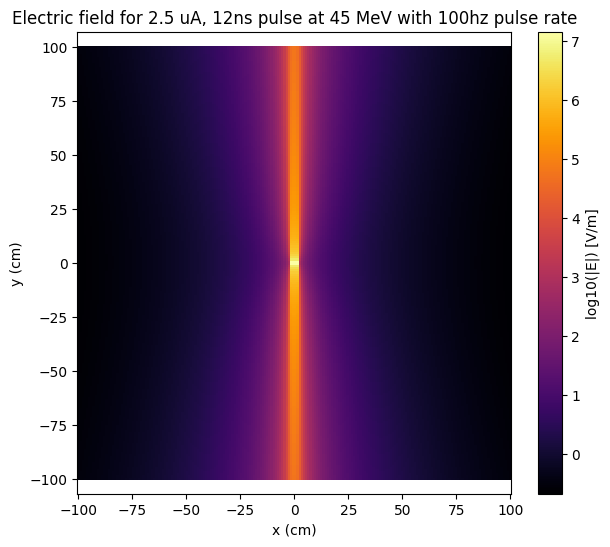

In [5]:
import numpy as np
import matplotlib.pyplot as plt
# Physical constants
eps0 = 8.854e-12
c = 3e8
# Parameters
Q = -150e-9          # total charge (C)
beta = 0.999920
duration = 1e-8  # 10 ns pulse
L0 = beta * c * duration   # rest-frame length of line charge (m)
gamma = 1/np.sqrt(1-beta**2)
N_samples = 7500      # number of discrete charges along the line

# Line charge distribution (rest frame, along x')
x_prime = np.linspace(-L0/2, L0/2, N_samples)
y_prime = np.zeros_like(x_prime)
z_prime = np.zeros_like(x_prime)
dq = Q / N_samples
print(Q)

# Observation grid in lab frame (z=0 plane)
grid_size = 200
extent = 1 #meters
x = np.linspace(-extent, extent, grid_size)
y = np.linspace(-extent, extent, grid_size)
X, Y = np.meshgrid(x, y)
Z = np.zeros_like(X)

# Map lab frame observation points -> rest frame coords
# Lorentz contraction along x
X_prime = gamma * X
Y_prime = Y
Z_prime = Z

# Initialize E fields in rest frame
Ex_p = np.zeros_like(X)
Ey_p = np.zeros_like(X)
Ez_p = np.zeros_like(X)

# Compute Coulomb field contribution from each dq
for xi, yi, zi in zip(x_prime, y_prime, z_prime):
    Rx = X_prime - xi
    Ry = Y_prime - yi
    Rz = Z_prime - zi
    R2 = Rx**2 + Ry**2 + Rz**2
    R3 = np.power(R2, 1.5)
    mask = R2 > 1e-18
    Ex_p[mask] += dq * Rx[mask] / (4*np.pi*eps0*R3[mask])
    Ey_p[mask] += dq * Ry[mask] / (4*np.pi*eps0*R3[mask])
    Ez_p[mask] += dq * Rz[mask] / (4*np.pi*eps0*R3[mask])

# Transform to lab frame
Ex_lab = Ex_p  # parallel (x) component unchanged
Ey_lab = gamma * Ey_p
Ez_lab = gamma * Ez_p

E_lab_mag = np.sqrt(Ex_lab**2 + Ey_lab**2 + Ez_lab**2)

# Plot
plt.figure(figsize=(7,6))
pcm = plt.pcolormesh(X*100, Y*100, np.log10(E_lab_mag), shading='auto', cmap='inferno')
plt.colorbar(pcm, label='log10(|E|) [V/m]')
plt.xlabel("x (cm)")
plt.ylabel("y (cm)")
plt.title("Electric field for 2.5 uA, 12ns pulse at 45 MeV with 100hz pulse rate")
plt.axis("equal")
plt.savefig("Lorentz_line_charge.png")
plt.show()


/tmp/ipykernel_18110/1765418904.py:111: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  beam_circle = plt.Circle((0, 0), beam.radius, color='cyan',


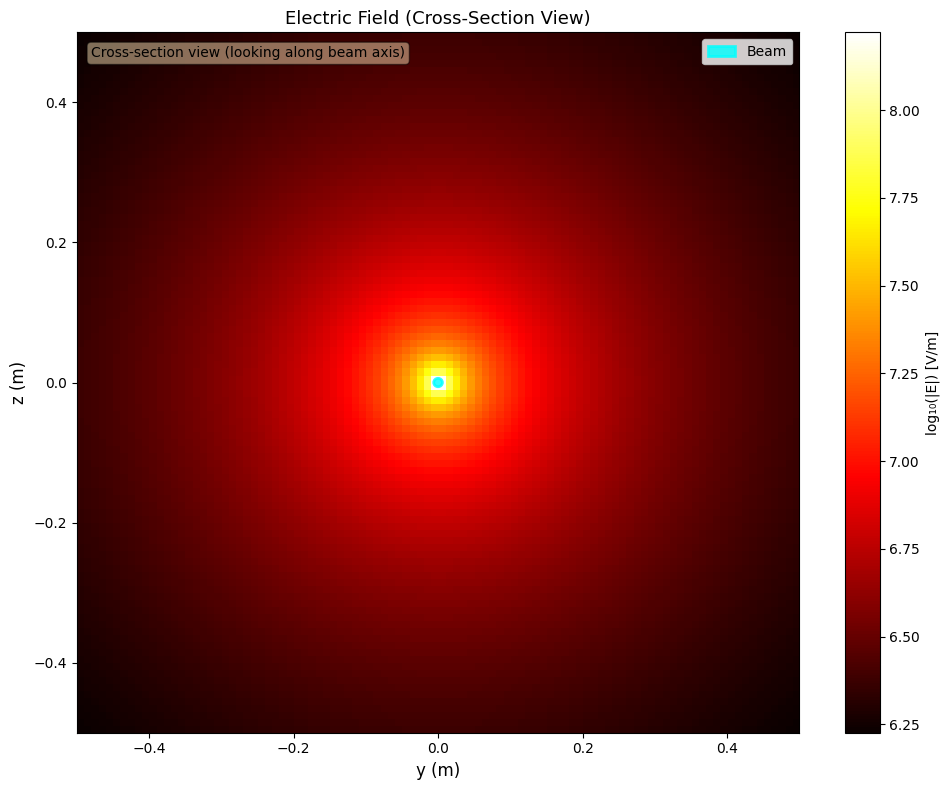

RELATIVISTIC BEAM PARAMETERS
Total charge:          1.00 nC
Beam duration:         0.00 ns
Beam radius:           6.00 mm
Beam length (lab):     0.09 cm
Velocity:              0.999859c = 3.000e+08 m/s
Lorentz factor (γ):    59.551
Linear charge density: 1111.27 nC/m
Peak current:          333.33 A

Physics Notes:
- Beam length = v × duration (in lab frame)
- Fields are enhanced by factor γ perpendicular to motion
- This models a bunched beam in a particle accelerator


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Physical constants
c = 3e8  # Speed of light (m/s)
epsilon_0 = 8.854e-12  # Permittivity of free space

class RelativisticBeam:
    def __init__(self, beam_radius, beam_duration, total_charge, velocity):
        """
        Initialize a relativistic particle beam
        
        Args:
            beam_radius: beam radius (m)
            beam_duration: duration of beam pulse (s)
            total_charge: total charge in beam (C)
            velocity: velocity as fraction of c (0 to 1)
        """
        self.radius = beam_radius
        self.beta = velocity  # v/c
        if self.beta >= 1:
            raise ValueError("Velocity must be less than c")
        self.gamma = 1 / np.sqrt(1 - self.beta**2)  # Lorentz factor
        
        # Calculate beam length in lab frame
        self.beam_duration = beam_duration
        self.length_lab = self.beta * c * beam_duration  # Lab frame length
        
        # Calculate linear charge density
        self.total_charge = total_charge
        self.lambda_0 = total_charge / self.length_lab  # Charge per unit length
        
    def electric_field(self, x, y, z, t):
        """Calculate electric field at point (x,y,z) at time t"""
        # Position of beam center at time t
        x_center = self.beta * c * t
        
        # Distance along beam axis
        x_rel = x - x_center
        
        # Perpendicular distance from beam axis
        r_perp = np.sqrt(y**2 + z**2)
        
        # Check if point is within beam length
        if abs(x_rel) > self.length_lab / 2:
            return np.zeros(3)
        
        # Check if inside the beam cylinder - return zero field inside
        if r_perp < self.radius:
            return np.zeros(3)
        
        # Electric field for cylindrical beam (perpendicular component, outside only)
        if r_perp > 1e-10:  # Avoid singularity
            E_perp = self.lambda_0 / (2 * np.pi * epsilon_0 * r_perp)
            E_y = E_perp * y / r_perp
            E_z = E_perp * z / r_perp
        else:
            E_y = E_z = 0
        
        # Lorentz transformation of fields (boost perpendicular components)
        E_x = 0  # No field along beam axis for uniform cylinder
        E_y_lab = self.gamma * E_y
        E_z_lab = self.gamma * E_z
        
        return np.array([E_x, E_y_lab, E_z_lab])

# Beam parameters (example: relativistic electron beam)
beam = RelativisticBeam(
    beam_radius=0.006,      # 6 mm radius
    beam_duration=3e-12,  # 100 picosecond pulse
    total_charge=1e-9,      # 0.5 nC total charge
    velocity=0.999859          # 0.9c (γ ≈ 2.29)
)

# Time snapshot - choose when beam center is at x=0
x_observation = 0.0
t = x_observation / (beam.beta * c) if beam.beta > 0 else 0

# Create visualization grids

# Cross-section view (y-z plane at x=0)
y_cross = np.linspace(-0.5, 0.5, 100)
z_cross = np.linspace(-0.5, 0.5, 100)
Y_cross, Z_cross = np.meshgrid(y_cross, z_cross)
beam_length = beam.length_lab

# Calculate fields for cross-section
E_mag_cross = np.zeros_like(Y_cross)
for i in range(Y_cross.shape[0]):
    for j in range(Y_cross.shape[1]):
        E = beam.electric_field(x_observation, Y_cross[i,j], Z_cross[i,j], t)
        E_mag_cross[i,j] = np.sqrt(E[1]**2 + E[2]**2)

# Avoid log(0) by setting minimum value
E_mag_cross[E_mag_cross < 1] = 1

# Create static plot with single heatmap
fig, ax1 = plt.subplots(1, 1, figsize=(10, 8))

# Electric field heatmap - Cross-section (looking along beam axis)
im1 = ax1.imshow(np.log10(E_mag_cross), extent=[y_cross.min(), y_cross.max(), z_cross.min(), z_cross.max()], 
                 origin='lower', cmap='hot', aspect='auto')
ax1.set_xlabel('y (m)', fontsize=12)
ax1.set_ylabel('z (m)', fontsize=12)
ax1.set_title(f'Electric Field (Cross-Section View)', fontsize=13)
cbar1 = plt.colorbar(im1, ax=ax1, label='log₁₀(|E|) [V/m]')


# Draw the beam cross-section (circular)
beam_circle = plt.Circle((0, 0), beam.radius, color='cyan', 
                         alpha=0.8, edgecolor='blue', linewidth=2, 
                         label='Beam')
ax1.add_patch(beam_circle)
ax1.legend(loc='upper right')
ax1.text(0.02, 0.98, 'Cross-section view (looking along beam axis)', transform=ax1.transAxes,
         verticalalignment='top', fontsize=10, bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))


plt.tight_layout()
plt.show()

# Print beam parameters
print("=" * 60)
print("RELATIVISTIC BEAM PARAMETERS")
print("=" * 60)
print(f"Total charge:          {beam.total_charge*1e9:.2f} nC")
print(f"Beam duration:         {beam.beam_duration*1e9:.2f} ns")
print(f"Beam radius:           {beam.radius*1000:.2f} mm")
print(f"Beam length (lab):     {beam_length*100:.2f} cm")
print(f"Velocity:              {beam.beta}c = {beam.beta*c:.3e} m/s")
print(f"Lorentz factor (γ):    {beam.gamma:.3f}")
print(f"Linear charge density: {beam.lambda_0*1e9:.2f} nC/m")
print(f"Peak current:          {beam.total_charge/beam.beam_duration:.2f} A")
print("=" * 60)
print("\nPhysics Notes:")
print("- Beam length = v × duration (in lab frame)")
print("- Fields are enhanced by factor γ perpendicular to motion")
print("- This models a bunched beam in a particle accelerator")


Completed 1/9: 1.0 MeV
Completed 2/9: 5.9 MeV
Completed 3/9: 10.8 MeV
Completed 4/9: 15.6 MeV
Completed 5/9: 20.5 MeV
Completed 6/9: 25.4 MeV
Completed 7/9: 30.2 MeV
Completed 8/9: 35.1 MeV
Completed 9/9: 40.0 MeV


/tmp/ipykernel_18110/2702561506.py:93: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.93, 0.99])


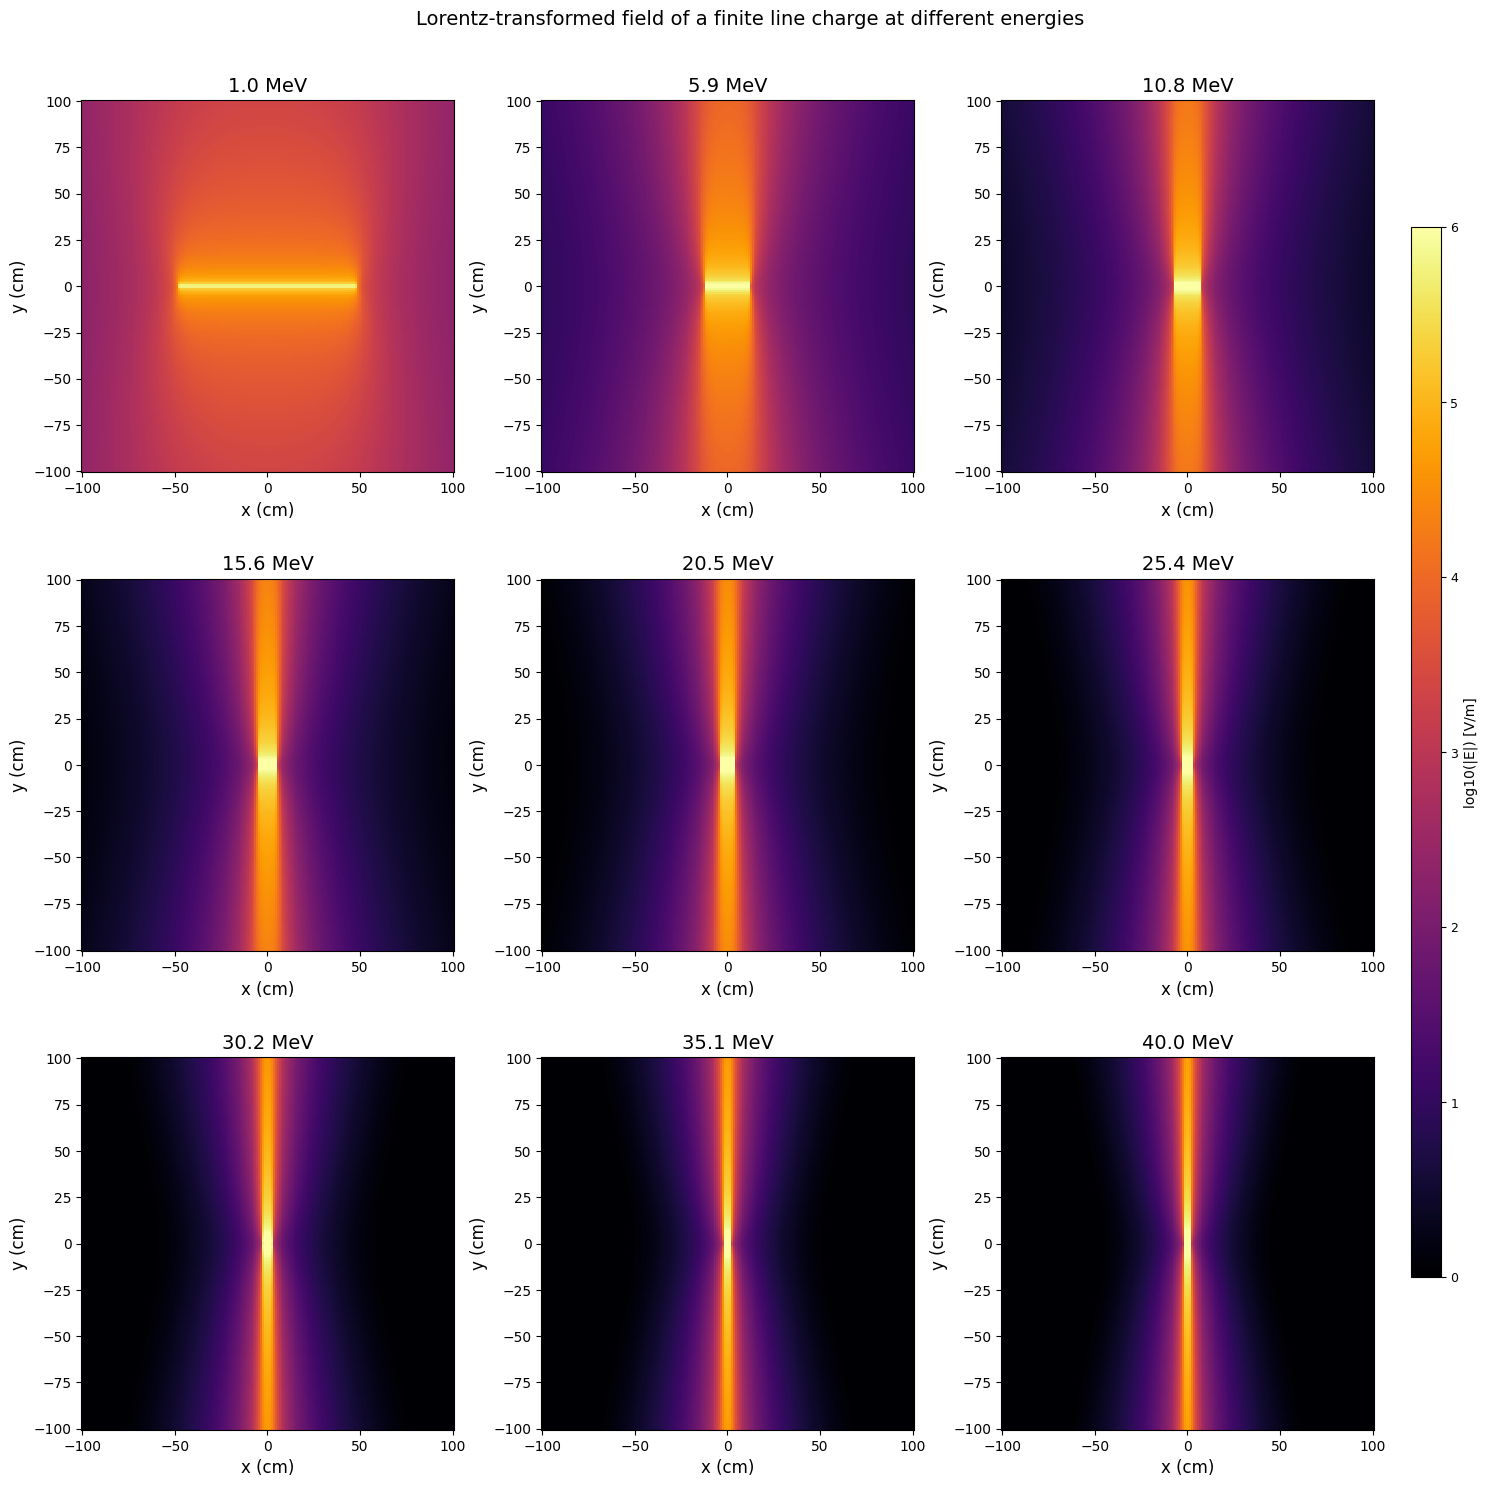

In [7]:
import numpy as np
import matplotlib.pyplot as plt
# Physical constants
eps0 = 8.854e-12
c = 3e8
m_e = 9.109e-31  # electron mass (kg)
e_charge = 1.602e-19  # elementary charge (C)

# Parameters
Q = -150e-9               # total charge (C)
duration = 1e-8  # 10 ns pulse
N_samples = 7500      # number of discrete charges along the line

# Energy levels from 1 MeV to 40 MeV
energies_MeV = np.linspace(1, 40, 9)

# Observation grid in lab frame (z=0 plane)
grid_size = 200
extent = 1 #meters
x = np.linspace(-extent, extent, grid_size)
y = np.linspace(-extent, extent, grid_size)
X, Y = np.meshgrid(x, y)
Z = np.zeros_like(X)

# Create 3x3 subplot
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

for idx, energy_MeV in enumerate(energies_MeV):
    # Convert energy to joules
    energy_J = energy_MeV * 1e6 * e_charge
    
    # Calculate gamma from kinetic energy: E_kinetic = (gamma - 1) * m_e * c^2
    gamma = 1 + energy_J / (m_e * c**2)
    
    # Calculate beta from gamma
    beta = np.sqrt(1 - 1/gamma**2)
    
    L0 = beta * c * duration   # rest-frame length of line charge (m)
    
    # Line charge distribution (rest frame, along x')
    x_prime = np.linspace(-L0/2, L0/2, N_samples)
    y_prime = np.zeros_like(x_prime)
    z_prime = np.zeros_like(x_prime)
    dq = Q / N_samples
    
    # Map lab frame observation points -> rest frame coords
    X_prime = gamma * X
    Y_prime = Y
    Z_prime = Z
    
    # Initialize E fields in rest frame
    Ex_p = np.zeros_like(X)
    Ey_p = np.zeros_like(X)
    Ez_p = np.zeros_like(X)
    
    # Compute Coulomb field contribution from each dq
    for xi, yi, zi in zip(x_prime, y_prime, z_prime):
        Rx = X_prime - xi
        Ry = Y_prime - yi
        Rz = Z_prime - zi
        R2 = Rx**2 + Ry**2 + Rz**2
        R3 = np.power(R2, 1.5)
        mask = R2 > 1e-18
        Ex_p[mask] += dq * Rx[mask] / (4*np.pi*eps0*R3[mask])
        Ey_p[mask] += dq * Ry[mask] / (4*np.pi*eps0*R3[mask])
        Ez_p[mask] += dq * Rz[mask] / (4*np.pi*eps0*R3[mask])
    
    # Transform to lab frame
    Ex_lab = Ex_p
    Ey_lab = gamma * Ey_p
    Ez_lab = gamma * Ez_p
    E_lab_mag = np.sqrt(Ex_lab**2 + Ey_lab**2 + Ez_lab**2)
    
    # Plot
    ax = axes[idx]
    pcm = ax.pcolormesh(X*100, Y*100, np.log10(E_lab_mag), shading='auto', cmap='inferno', vmin=0, vmax=6)
    ax.set_xlabel("x (cm)", fontsize=12)
    ax.set_ylabel("y (cm)", fontsize=12)
    ax.set_title(f"{energy_MeV:.1f} MeV", fontsize=14)
    ax.set_aspect("equal")
    ax.tick_params(labelsize=10)
    
    print(f"Completed {idx+1}/9: {energy_MeV:.1f} MeV")

# Add colorbar
fig.subplots_adjust(right=0.92)
cbar_ax = fig.add_axes([0.94, 0.15, 0.02, 0.7])
cbar = fig.colorbar(pcm, cax=cbar_ax, label='log10(|E|) [V/m]')
cbar.ax.tick_params(labelsize=9)

plt.suptitle("Lorentz-transformed field of a finite line charge at different energies", fontsize=14, y=0.995)
plt.tight_layout(rect=[0, 0, 0.93, 0.99])
plt.savefig("Lorentz_line_charge_9energies.png", dpi=150, bbox_inches='tight')
plt.show()

6399


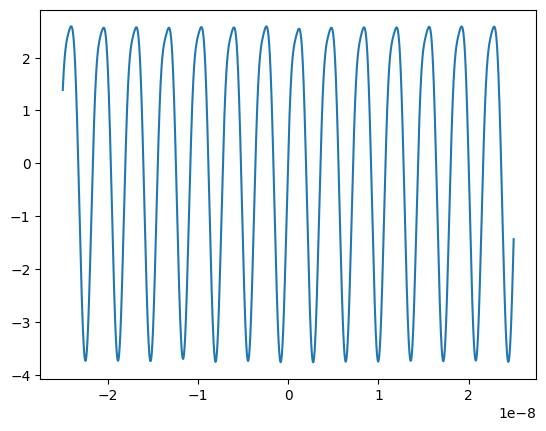

In [8]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
data = pd.read_csv('test1.csv').to_numpy()
t = data[:,0]
v = data[:,1]
plt.plot(t, v)
print(len(t))
